In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})

folder = Path.cwd()
if not (folder / "harmonic.py").exists():
    folder = folder.parent
sys.path.insert(0, str(folder))

from harmonic import HarmonicOscillator

<Figure size 1000x500 with 0 Axes>

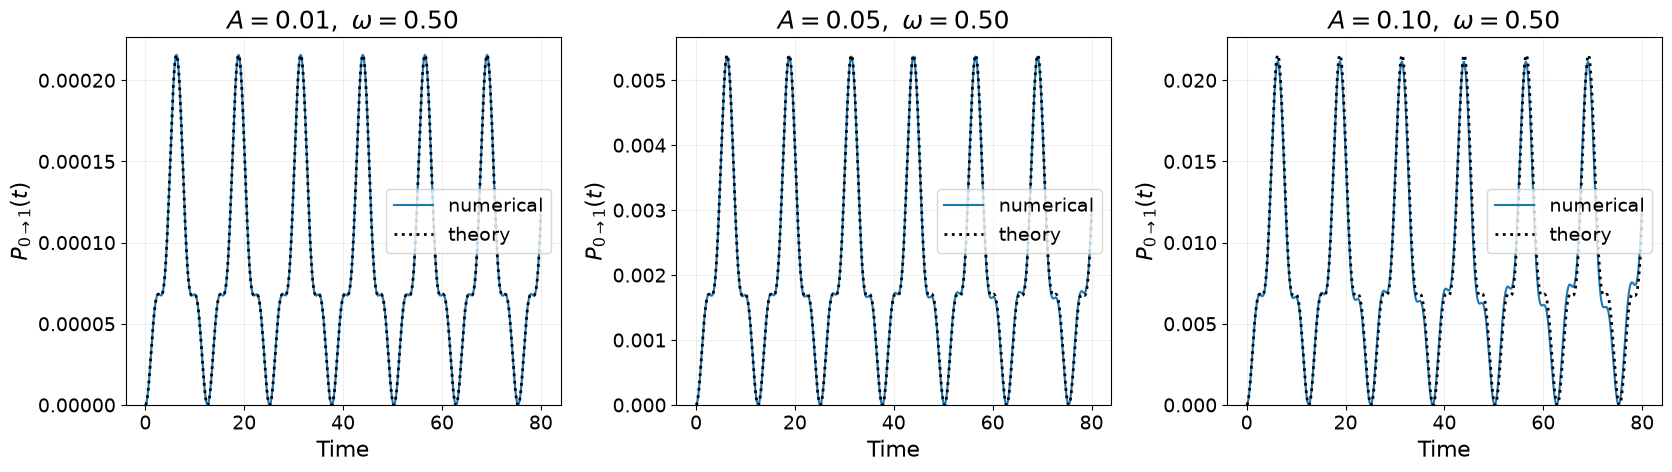

In [12]:
# Parameters
omega = 0.5
A_values = [0.01, 0.05, 0.1]
n = 128
L = 12
dt = 0.01
tmax = 80

ho = HarmonicOscillator(boundary=(-L, L), n=n)
_, basis = ho.eigenstates()

phi0 = basis[:, 0]
phi1 = basis[:, 1]
times = np.linspace(0, tmax, int(np.ceil(tmax / dt)) + 1)

plt.figure(figsize=(10, 5))
M10 = np.exp(-0.25) / np.sqrt(2)

# Time integrals for full first-order theory
J_minus = np.expm1(1j * (1 - omega) * times) / (1j * (1 - omega))
J_plus = np.expm1(1j * (1 + omega) * times) / (1j * (1 + omega))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, A in zip(axes, A_values):
    psi = phi0.copy()
    P_num = np.zeros(len(times))

    for i in range(1, len(times)):
        psi = ho.time_evolution(
            [times[i]],
            omega=omega,
            A=A,
            psi0=psi,
            t0=times[i - 1]
        )
        P_num[i] = np.abs(np.vdot(phi1, psi))**2

    P_first = (A * M10 / 2)**2 * np.abs(J_minus + J_plus)**2

    ax.plot(times, P_num, label="numerical")
    ax.plot(
        times, P_first, "k:", linewidth=2,
        label="theory"
    )

    ax.set_title(rf"$A={A:.2f},\ \omega={omega:.2f}$")
    ax.set_xlabel("Time")
    ax.set_ylabel(r"$P_{0\to1}(t)$")
    ax.set_ylim(bottom=0)
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [3]:
# Matrix elements S[m,n] = <m|sin(x)|n>
S = basis.conj().T @ (np.sin(ho.xi())[:, None] * basis)

# Every second-order path 0 → m → 1 contains this product
two_step_products = S[1, :] * S[:, 0]

print("One-step coupling:", np.abs(S[1, 0]))
print("Largest two-step product:", np.max(np.abs(two_step_products)))

One-step coupling: 0.5506953149031826
Largest two-step product: 1.367386987667679e-14
